# 03 — Análisis exploratorio (EDA)

**Pregunta del caso:** ¿qué perfiles de conductor y vehículo tienen mayor costo esperado de
siniestros (prima pura) y cuánto se apartan del promedio de la cartera?

El notebook `02_historia` ya respondió H1–H3 con **edad, BonusMalus y zona**. Este notebook completa
el EDA con el resto: estructura, estadísticas descriptivas, distribuciones, correlaciones, las
variables del **vehículo** (antigüedad, potencia, combustible, marca), **densidad** y **región**,
cruces para ver si un efecto es propio o es confusión con otra variable, y **outliers**.

**Fuente:** `export/polizas.csv` y `export/siniestros.csv`, el dataset final que genera el ETL
(`python src/etl.py`). No hace falta la base de datos: es lo mismo que usa Power BI.

**Reglas que seguimos en todo el notebook**
- Los indicadores se calculan **sumando y dividiendo** (siniestros ÷ exposición), nunca promediando.
- Al lado de cada indicador va **cuánta exposición tiene el segmento**: un número sobre el 0,5 % de
  la cartera no vale lo mismo que uno sobre el 25 %.
- Cada frecuencia lleva su **intervalo de confianza del 95 %** (aproximación de Poisson: ±1,96·√n ÷ exposición).
- La prima pura se mide **con tope** (p99 = 16.451 €), por lo que se explicó en H3.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Funciona en la carpeta del TP (notebooks/ -> ../export) y en Google Colab (export/ subida a la raíz)
EXPORT = next((p for p in [Path("../export"), Path("export")] if (p / "polizas.csv").exists()), None)
if EXPORT is None:
    raise FileNotFoundError("No encuentro polizas.csv: corré antes `python src/etl.py` "
                            "o, en Colab, subí la carpeta export/ con polizas.csv y siniestros.csv")
IMG = Path("../presentacion/img") if EXPORT == Path("../export") else Path("img")
IMG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", None)

# Mismo estilo que notebooks/02_historia.ipynb
AZUL, GRIS, NARANJA, TINTA = "#2a78d6", "#a3a29c", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.figsize": (10, 5.2), "figure.dpi": 110, "savefig.dpi": 160,
    "font.size": 12, "axes.titlesize": 15, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": TINTA, "xtick.color": TINTA, "ytick.color": TINTA,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ecebe7", "axes.axisbelow": True,
})

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(IMG / f"{nombre}.png", bbox_inches="tight", facecolor="white")
    plt.show()

# franja_bm ('050') y franja_vehage ('00') son etiquetas: se leen como texto para no perder los ceros
polizas = pd.read_csv(EXPORT / "polizas.csv", dtype={"franja_bm": str, "franja_vehage": str})
siniestros = pd.read_csv(EXPORT / "siniestros.csv")
print(f"{len(polizas):,} pólizas · {len(siniestros):,} siniestros")

678,013 pólizas · 26,444 siniestros


## 1. Estructura del dataset final

Una fila por póliza. Las columnas son de cuatro tipos: **medidas** (lo que se suma), **conductor**,
**vehículo y territorio**, y **marcas de calidad** (`flag_`) que dejó la limpieza.

In [2]:
tipos = pd.DataFrame({"tipo": polizas.dtypes.astype(str),
                      "valores_distintos": polizas.nunique(),
                      "nulos": polizas.isna().sum()})
tipos

,tipo,valores_distintos,nulos
idpol,int64,678013,0
exposure,float64,106,0
siniestros,int64,11,0
monto,float64,12019,0
monto_topeado,float64,11795,0
siniestros_grandes,int64,2,0
drivage,int64,83,0
franja_edad,str,8,0
bonusmalus,int64,115,0
franja_bm,str,4,0


**Lectura:** 23 columnas, **sin nulos** (la limpieza ya los controló). `idpol` tiene tantos valores
distintos como filas: una fila por póliza, como se esperaba. Las franjas son texto a propósito.

## 2. Estadísticas descriptivas

Variables numéricas del conductor y del vehículo. Mostramos percentiles 1 y 99 para ver las colas.

In [3]:
numericas = ["drivage", "bonusmalus", "vehage", "vehpower", "density", "exposure"]
desc = polizas[numericas].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
desc

,count,mean,std,min,1%,25%,50%,75%,99%,max
drivage,"678,013.000",45.499,14.137,18.000,20.000,34.000,44.000,55.000,80.000,100.000
bonusmalus,"678,013.000",59.762,15.637,50.000,50.000,50.000,50.000,64.000,106.000,230.000
vehage,"678,013.000",7.044,5.666,0.000,0.000,2.000,6.000,11.000,21.000,100.000
vehpower,"678,013.000",6.455,2.051,4.000,4.000,5.000,6.000,7.000,13.000,15.000
density,"678,013.000","1,792.422","3,958.647",1.000,10.000,92.000,393.000,"1,658.000","27,000.000","27,000.000"
exposure,"678,013.000",0.529,0.364,0.003,0.008,0.180,0.490,0.990,1.000,1.000


In [4]:
# Indicadores de toda la cartera: son el "1,0" de todas las relatividades
EXPO = polizas["exposure"].sum()
FREC = polizas["siniestros"].sum() / EXPO
SEV = polizas["monto_topeado"].sum() / polizas["siniestros"].sum()
PP = polizas["monto_topeado"].sum() / EXPO
print(f"Exposición total:      {EXPO:,.1f} años-póliza")
print(f"Frecuencia:            {FREC:.4f} siniestros por año-póliza")
print(f"Severidad (con tope):  {SEV:,.2f} €")
print(f"Prima pura (con tope): {PP:,.2f} € por año-póliza")
print(f"Pólizas sin siniestros: {100 * (polizas['siniestros'] == 0).mean():.1f} %")

Exposición total:      358,360.1 años-póliza
Frecuencia:            0.0738 siniestros por año-póliza
Severidad (con tope):  1,569.16 €
Prima pura (con tope): 115.79 € por año-póliza
Pólizas sin siniestros: 96.3 %


**Lectura:**
- **Edad:** media 45 años, de 18 a 100. El 1 % más joven tiene 20 años o menos.
- **BonusMalus:** la **mediana es 50** (el mejor nivel): más de la mitad de la cartera tiene la máxima
  bonificación. Solo el 1 % pasa de 106.
- **Antigüedad del vehículo:** mediana 6 años; el máximo de 100 es el código sospechoso de "desconocido" (Q10).
- **Densidad:** muy asimétrica (mediana 393, media 1.792, máximo 27.000 = París). Por eso conviene
  mirarla en escala logarítmica o en deciles.
- **Exposición:** mediana 0,49: la mitad de las pólizas estuvo cubierta menos de medio año. Por eso
  nunca se puede promediar la cantidad de siniestros.
- El **96 % de las pólizas no tuvo ningún siniestro**: el evento que estudiamos es raro.

## 3. Distribución de las variables numéricas

Histogramas **ponderados por exposición** (cuántos años-póliza hay en cada valor), que es lo que
pesa en los indicadores.

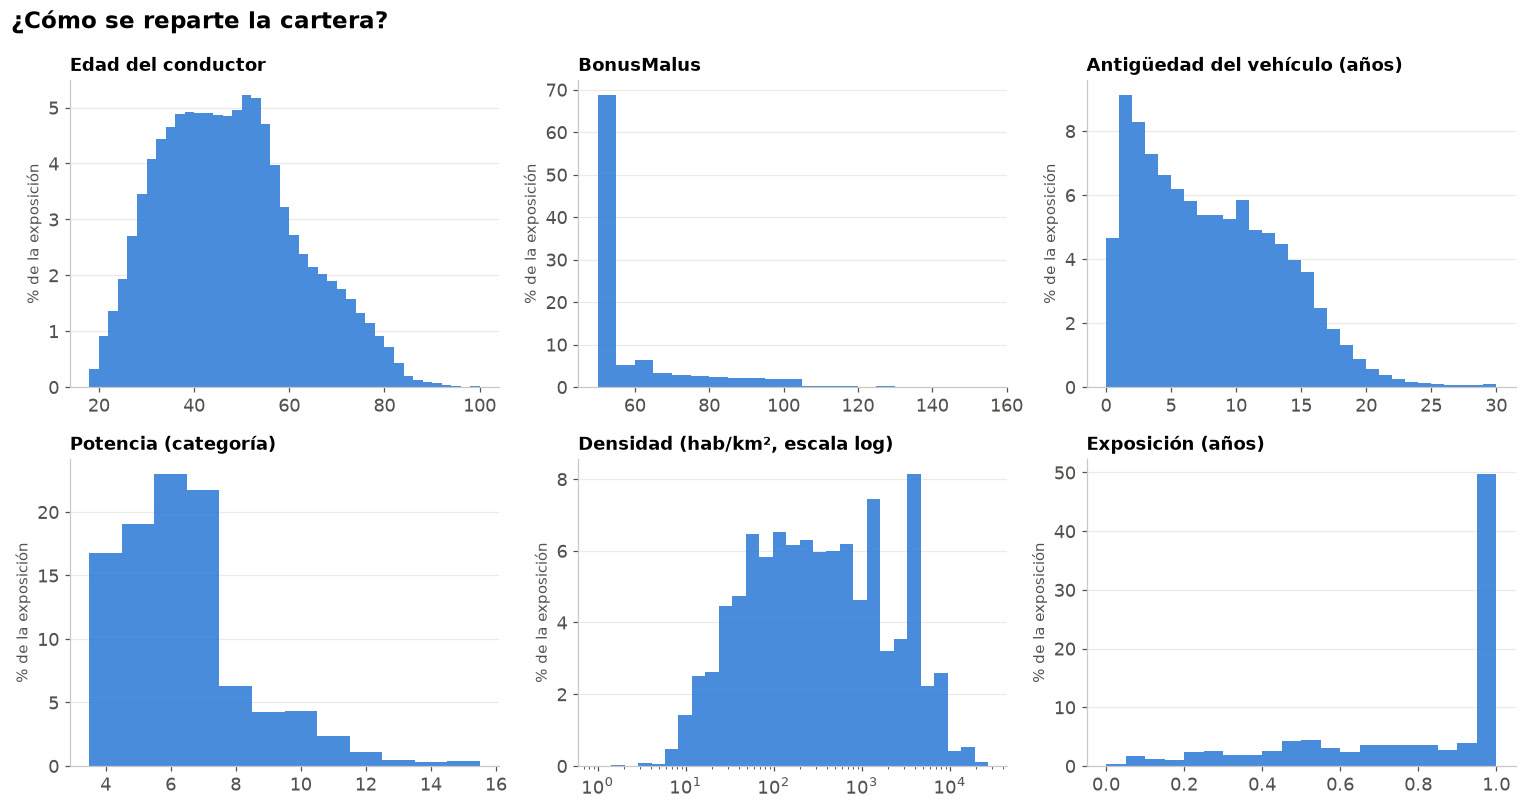

In [5]:
fig, ejes = plt.subplots(2, 3, figsize=(14, 7.5))
config = [("drivage", "Edad del conductor", np.arange(18, 101, 2), False),
          ("bonusmalus", "BonusMalus", np.arange(50, 160, 5), False),
          ("vehage", "Antigüedad del vehículo (años)", np.arange(0, 31, 1), False),
          ("vehpower", "Potencia (categoría)", np.arange(3.5, 15.6, 1), False),
          ("density", "Densidad (hab/km², escala log)", np.logspace(0, np.log10(27000), 30), True),
          ("exposure", "Exposición (años)", np.linspace(0, 1, 21), False)]
for ax, (col, titulo, bins, log) in zip(ejes.flat, config):
    ax.hist(polizas[col], bins=bins, weights=polizas["exposure"] / EXPO * 100, color=AZUL, alpha=0.85)
    if log:
        ax.set_xscale("log")
    ax.set_title(titulo, fontsize=12)
    ax.set_ylabel("% de la exposición", fontsize=10)
fig.suptitle("¿Cómo se reparte la cartera?", x=0.01, ha="left", fontweight="bold", fontsize=15)
guardar(fig, "eda_distribuciones")

**Lectura:**
- **Edad:** campana ancha entre 30 y 60; muy poca exposición en 18–21 (por eso esa franja es inestable).
- **BonusMalus:** casi todo apilado en 50, con una cola larga hacia la derecha. No es una variable
  "normal": se analiza mejor en franjas.
- **Antigüedad:** pico en autos de 0–2 años y caída gradual; casi no hay autos de más de 20 años.
- **Potencia:** concentrada en 4–7; las potencias altas (11+) son pocas.
- **Densidad:** en escala log se ve una cartera repartida entre pueblos y ciudades medianas, con un
  bloque aparte en las densidades más altas (grandes ciudades).
- **Exposición:** muchas pólizas cortas y un pico en 1 año (las que estuvieron todo el período).

## 4. Variables categóricas: ¿dónde está la cartera?

In [6]:
def peso(col):
    t = polizas.groupby(col)["exposure"].sum()
    return (100 * t / t.sum()).sort_values(ascending=False).round(1).rename("% exposición")

for col in ["vehgas", "area", "vehbrand", "region_2016"]:
    print(f"--- {col}")
    print(peso(col).to_string(), "\n")

--- vehgas
vehgas
Regular   52.400
Diesel    47.600 

--- area
area
C   29.100
D   21.500
E   17.800
A   17.300
B   12.000
F    2.300 

--- vehbrand
vehbrand
B1    26.600
B2    26.500
B12   18.100
B3     8.000
B5     5.600
B6     4.400
B4     3.800
B10    2.600
B11    1.900
B13    1.900
B14    0.600 

--- region_2016
region_2016
Centre-Val de Loire          28.700
Auvergne-Rhône-Alpes         13.300
Provence-Alpes-Côte d'Azur   10.000
Île-de-France                 8.400
Nouvelle-Aquitaine            7.800
Bretagne                      7.700
Hauts-de-France               6.500
Pays de la Loire              6.100
Occitanie                     6.100
Normandie                     2.700
Bourgogne-Franche-Comté       1.600
Grand Est                     0.700
Corse                         0.500 



**Lectura:**
- **Combustible:** cartera pareja (≈ 48 % diésel, 52 % nafta).
- **Marca:** muy concentrada: **B1, B2 y B12 suman el 71 %**. Varias marcas tienen menos del 3 %.
- **Región:** **Centre-Val de Loire tiene el 29 %** de la exposición, mucho más que su peso en la
  población de Francia. La cartera **no es representativa del país**: es la cartera de esta aseguradora.
  Corse y Grand Est pesan menos del 1 %.

## 5. Correlaciones entre variables

Usamos **Spearman** (correlación por rangos) porque varias variables son asimétricas
(densidad, BonusMalus) y nos interesa si "suben juntas", no si la relación es una recta.

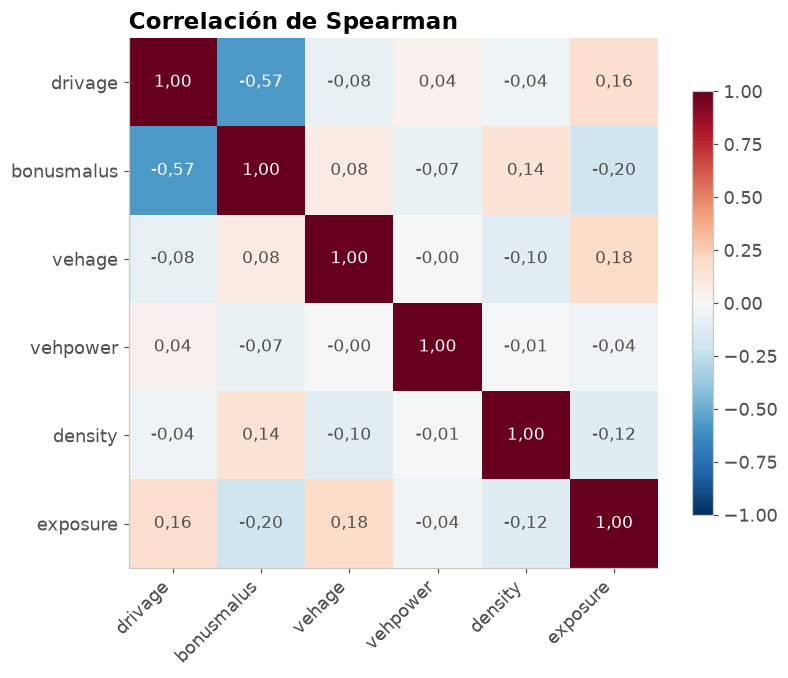

,drivage,bonusmalus,vehage,vehpower,density,exposure
drivage,1.000,-0.570,-0.080,0.040,-0.040,0.160
bonusmalus,-0.570,1.000,0.080,-0.070,0.140,-0.200
vehage,-0.080,0.080,1.000,-0.000,-0.100,0.180
vehpower,0.040,-0.070,-0.000,1.000,-0.010,-0.040
density,-0.040,0.140,-0.100,-0.010,1.000,-0.120
exposure,0.160,-0.200,0.180,-0.040,-0.120,1.000


In [7]:
corr = polizas[numericas].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numericas)), numericas, rotation=45, ha="right")
ax.set_yticks(range(len(numericas)), numericas)
ax.grid(False)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}".replace(".", ","), ha="center", va="center",
                color="white" if abs(v) > 0.5 else TINTA, fontsize=11)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlación de Spearman")
guardar(fig, "eda_correlaciones")
corr.round(2)

**Lectura:**
- La única correlación fuerte es **edad ↔ BonusMalus (−0,57)**: los conductores jóvenes tienen
  BonusMalus alto porque recién empiezan (arrancan en 100 y bajan con los años sin choques).
  Es la **confusión** que ya vimos en `02_historia`: parte del "efecto edad" es en realidad efecto
  BonusMalus, y viceversa.
- El resto de las correlaciones son débiles (|ρ| < 0,2): las variables del vehículo y la densidad
  aportan información **distinta** a la del conductor.
- Correlación no es causa, y una correlación baja tampoco garantiza que no haya confusión dentro de
  algún segmento: por eso en la sección 7 cruzamos variables.

## 6. Frecuencia y prima pura por variable (con la exposición al lado)

Una misma función resume cualquier variable, y un mismo gráfico la muestra:
arriba, **cuánta cartera** hay en cada categoría; abajo, la **relatividad** (1,0 = promedio) de
frecuencia y de prima pura con tope, con el intervalo de confianza de la frecuencia.

In [8]:
def resumen(col, df=polizas):
    g = df.groupby(col, observed=True).agg(
        polizas=("idpol", "size"), exposicion=("exposure", "sum"),
        siniestros=("siniestros", "sum"), monto_tope=("monto_topeado", "sum"))
    g["pct_exposicion"] = 100 * g["exposicion"] / EXPO
    g["frecuencia"] = g["siniestros"] / g["exposicion"]
    g["ic95"] = 1.96 * np.sqrt(g["siniestros"]) / g["exposicion"]        # aproximación de Poisson
    g["rel_frecuencia"] = g["frecuencia"] / FREC
    g["rel_prima_pura"] = g["monto_tope"] / g["exposicion"] / PP
    return g

def grafico(tabla, titulo, nombre, xlabel, rotar=0):
    fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(11, 6.8), sharex=True,
                                        gridspec_kw={"height_ratios": [1, 2.3]})
    x = np.arange(len(tabla))
    etiquetas = [str(i) for i in tabla.index]
    arriba.bar(x, tabla["pct_exposicion"], color=GRIS, width=0.6)
    arriba.set_ylabel("% expo.", fontsize=10)
    arriba.set_title(titulo)
    abajo.bar(x - 0.17, tabla["rel_frecuencia"], width=0.34, color=AZUL, label="frecuencia",
              yerr=tabla["ic95"] / FREC, error_kw={"ecolor": TINTA, "capsize": 3, "lw": 1})
    abajo.bar(x + 0.17, tabla["rel_prima_pura"], width=0.34, color=NARANJA, label="prima pura (con tope)")
    abajo.axhline(1, color=TINTA, ls="--", lw=1.1)
    abajo.set_ylabel("veces el promedio")
    abajo.set_xticks(x, etiquetas, rotation=rotar, ha="right" if rotar else "center")
    abajo.set_xlabel(xlabel)
    abajo.legend(frameon=False, loc="upper left")
    guardar(fig, nombre)

COLS = ["polizas", "pct_exposicion", "frecuencia", "ic95", "rel_frecuencia", "rel_prima_pura"]

### 6.1 Antigüedad del vehículo

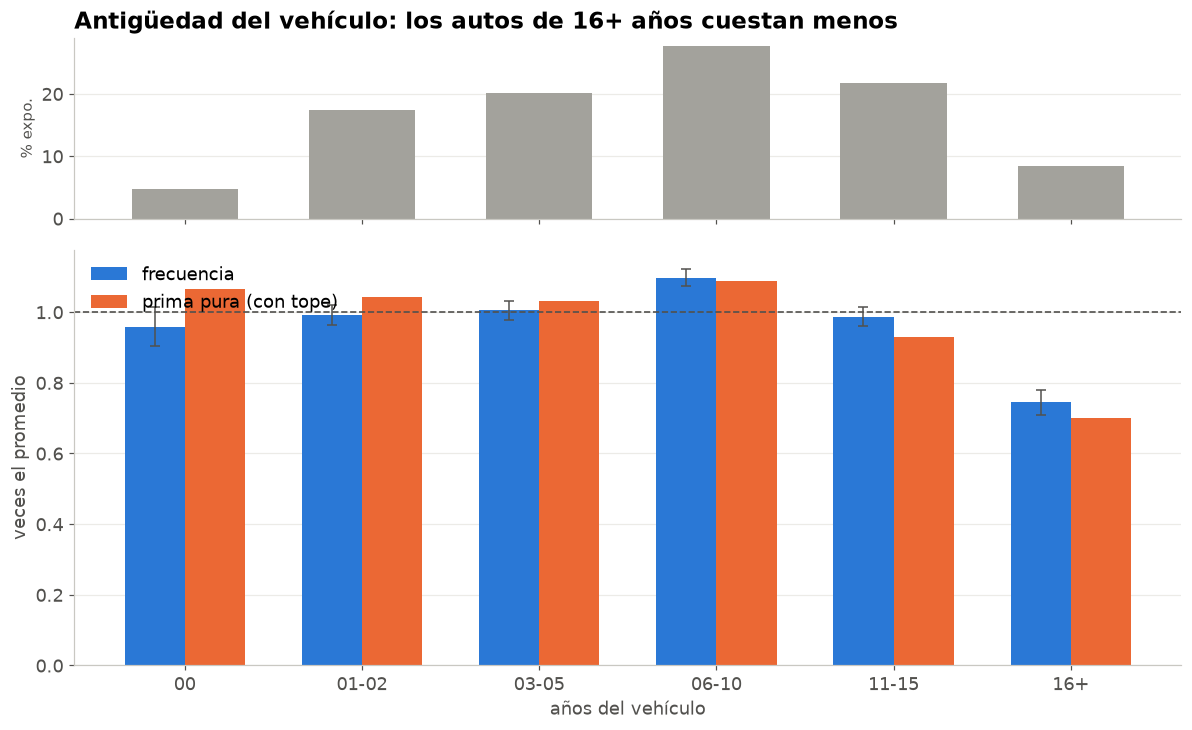

,polizas,pct_exposicion,frecuencia,ic95,rel_frecuencia,rel_prima_pura
franja_vehage,,,,,,
00,57739,4.659,0.071,0.004,0.959,1.065
01-02,130408,17.424,0.073,0.002,0.991,1.043
03-05,132490,20.097,0.074,0.002,1.006,1.031
06-10,171594,27.619,0.081,0.002,1.097,1.088
11-15,134063,21.753,0.073,0.002,0.987,0.929
16+,51719,8.447,0.055,0.003,0.745,0.700


In [9]:
t = resumen("franja_vehage")
grafico(t, "Antigüedad del vehículo: los autos de 16+ años cuestan menos", "eda_vehage", "años del vehículo")
t[COLS]

**Lectura:** de 0 a 15 años la frecuencia se mantiene cerca del promedio (con un leve pico en 6–10).
Los autos de **16 años o más** tienen una frecuencia ≈ 25 % menor y una prima pura ≈ 30 % menor,
con un intervalo de confianza que no toca el 1,0: la diferencia es real, no ruido.
*Suposición* (no está en los datos): los autos viejos se usan menos kilómetros al año.
Recordar que la franja 16+ incluye los 48 autos con antigüedad 99/100 (Q10); son tan pocos que no mueven el resultado.

### 6.2 Potencia del vehículo

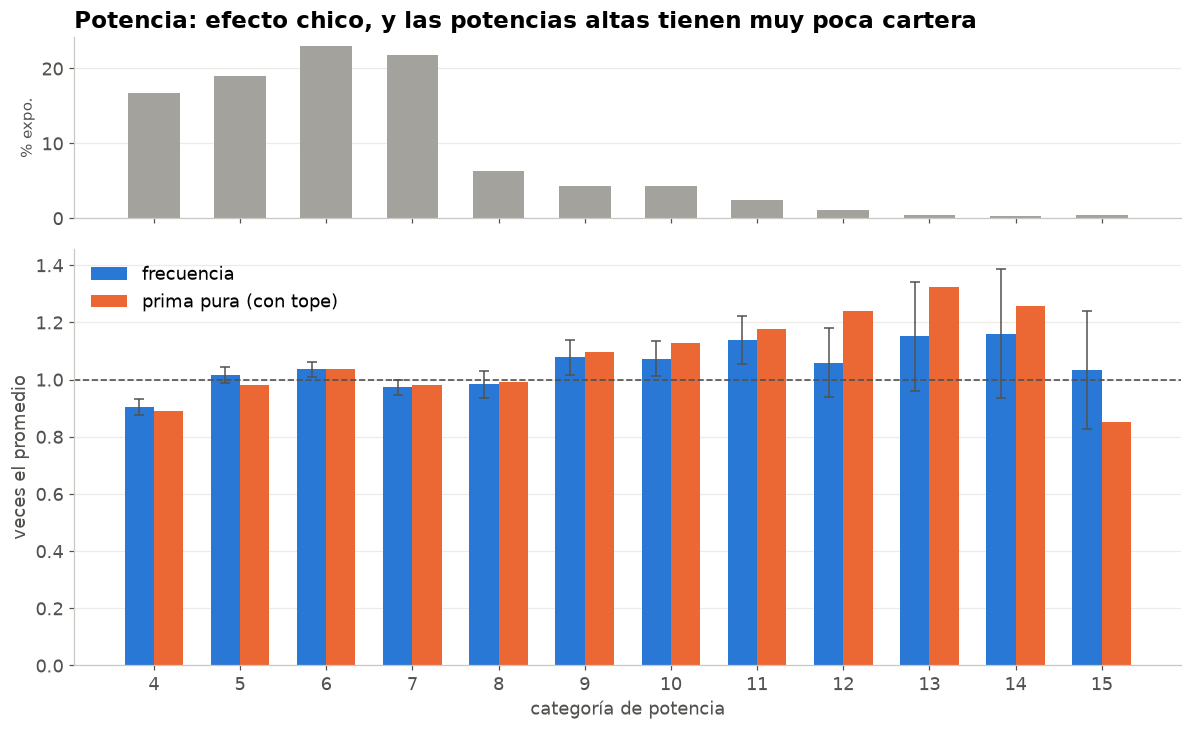

,polizas,pct_exposicion,frecuencia,ic95,rel_frecuencia,rel_prima_pura
vehpower,,,,,,
4,115349,16.758,0.067,0.002,0.903,0.890
5,124821,19.017,0.075,0.002,1.017,0.982
6,148976,23.021,0.076,0.002,1.036,1.036
7,145401,21.743,0.072,0.002,0.973,0.982
8,46956,6.327,0.073,0.004,0.983,0.992
9,30085,4.280,0.080,0.004,1.078,1.096
10,31354,4.288,0.079,0.004,1.073,1.128
11,18352,2.369,0.084,0.006,1.140,1.176
12,8214,1.058,0.078,0.009,1.058,1.238


In [10]:
t = resumen("vehpower")
grafico(t, "Potencia: efecto chico, y las potencias altas tienen muy poca cartera", "eda_vehpower", "categoría de potencia")
t[COLS]

**Lectura:** la relación es **débil**. La potencia 4 está un 10 % por debajo del promedio; de la
9 a la 14 la prima pura sube a 1,1–1,3 (la 15 vuelve a bajar a 0,85). Pero las potencias 12–15 suman **menos del 2,5 %** de la
exposición y sus intervalos de confianza son enormes (hasta ±20 %): no permiten afirmar nada por separado.
Para una tarifa convendría agrupar en 3 o 4 franjas (ej. 4 · 5–8 · 9+).

### 6.3 Combustible

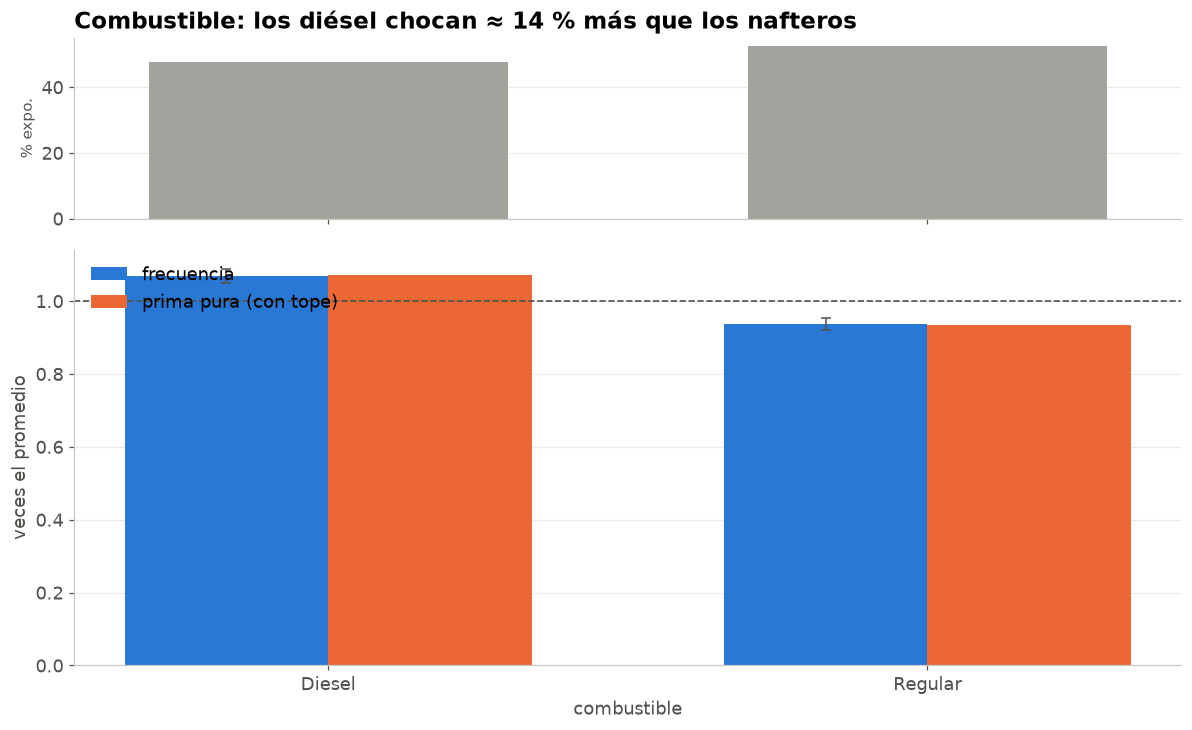

,polizas,pct_exposicion,frecuencia,ic95,rel_frecuencia,rel_prima_pura
vehgas,,,,,,
Diesel,332136,47.602,0.079,0.001,1.068,1.072
Regular,345877,52.398,0.069,0.001,0.938,0.935


In [11]:
t = resumen("vehgas")
grafico(t, "Combustible: los diésel chocan ≈ 14 % más que los nafteros", "eda_vehgas", "combustible")
t[COLS]

**Lectura:** diésel tiene **1,07×** de frecuencia y prima pura contra **0,94×** de nafta (Regular):
el diésel choca ≈ 14 % más seguido. Con ≈ 170.000 años-póliza en cada grupo, los intervalos son
chicos: la diferencia es estadísticamente clara. En la sección 7 vemos si es un efecto propio o si
los diésel tienen otro perfil de conductor.

### 6.4 Marca del vehículo (anonimizada)

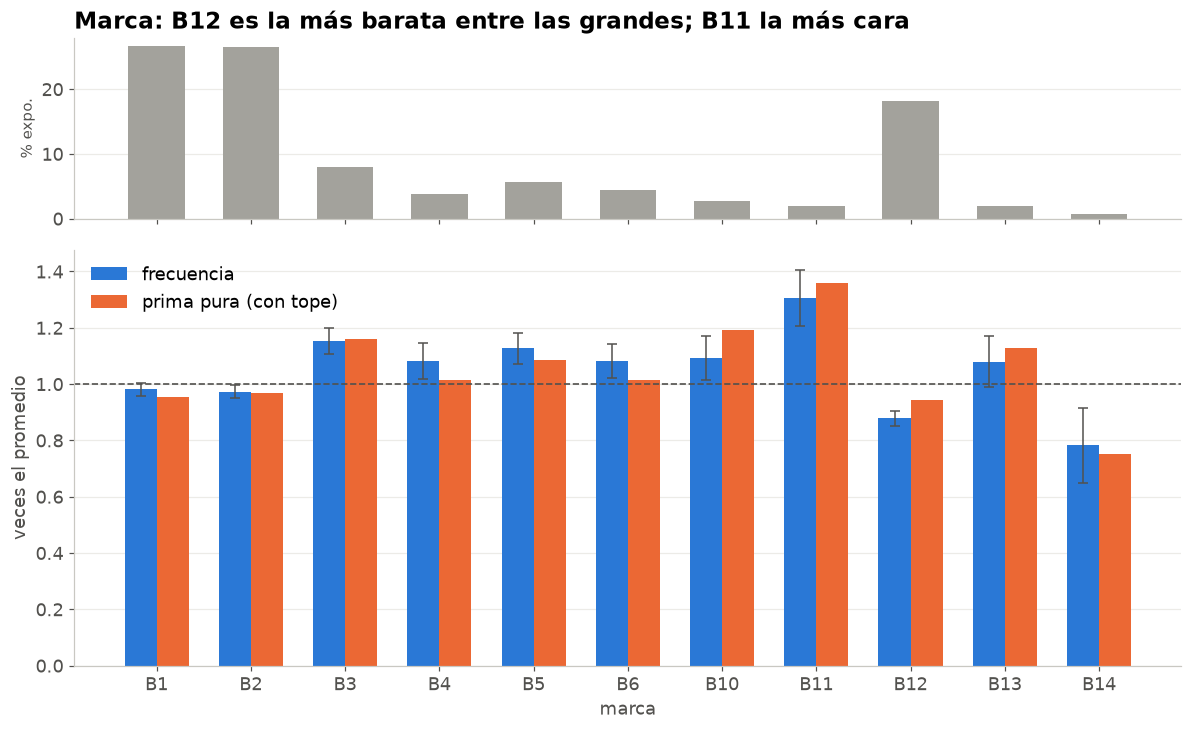

,polizas,pct_exposicion,frecuencia,ic95,rel_frecuencia,rel_prima_pura
vehbrand,,,,,,
B1,162736,26.598,0.072,0.002,0.981,0.953
B2,159861,26.460,0.072,0.002,0.973,0.967
B3,53395,7.974,0.085,0.003,1.152,1.159
B4,25179,3.843,0.080,0.005,1.082,1.014
B5,34753,5.576,0.083,0.004,1.127,1.085
B6,28548,4.375,0.080,0.004,1.082,1.013
B10,17707,2.648,0.081,0.006,1.092,1.194
B11,13585,1.921,0.096,0.007,1.307,1.357
B12,166024,18.083,0.065,0.002,0.878,0.944


In [12]:
t = resumen("vehbrand")
t = t.loc[sorted(t.index, key=lambda m: int(m[1:]))]       # orden B1, B2, ..., B14
grafico(t, "Marca: B12 es la más barata entre las grandes; B11 la más cara", "eda_vehbrand", "marca")
t[COLS]

**Lectura:**
- Entre las tres marcas grandes, **B1 y B2 están en el promedio** y **B12 un 12 % por debajo** en frecuencia.
- **B11** es la más cara (1,31× frecuencia, 1,36× prima pura) pero tiene solo el 1,9 % de la exposición.
- Como la marca está anonimizada, el resultado no se puede traducir a "tal fabricante"; además
  puede esconder otras cosas (tipo de auto, antigüedad). Lo revisamos en la sección 7.

### 6.5 Densidad de población (en deciles)

`Area` (A–F) es una versión en tramos de la densidad (Q13). Acá usamos la densidad en **deciles**
(10 grupos con ≈ la misma cantidad de pólizas) para ver la relación con más detalle.

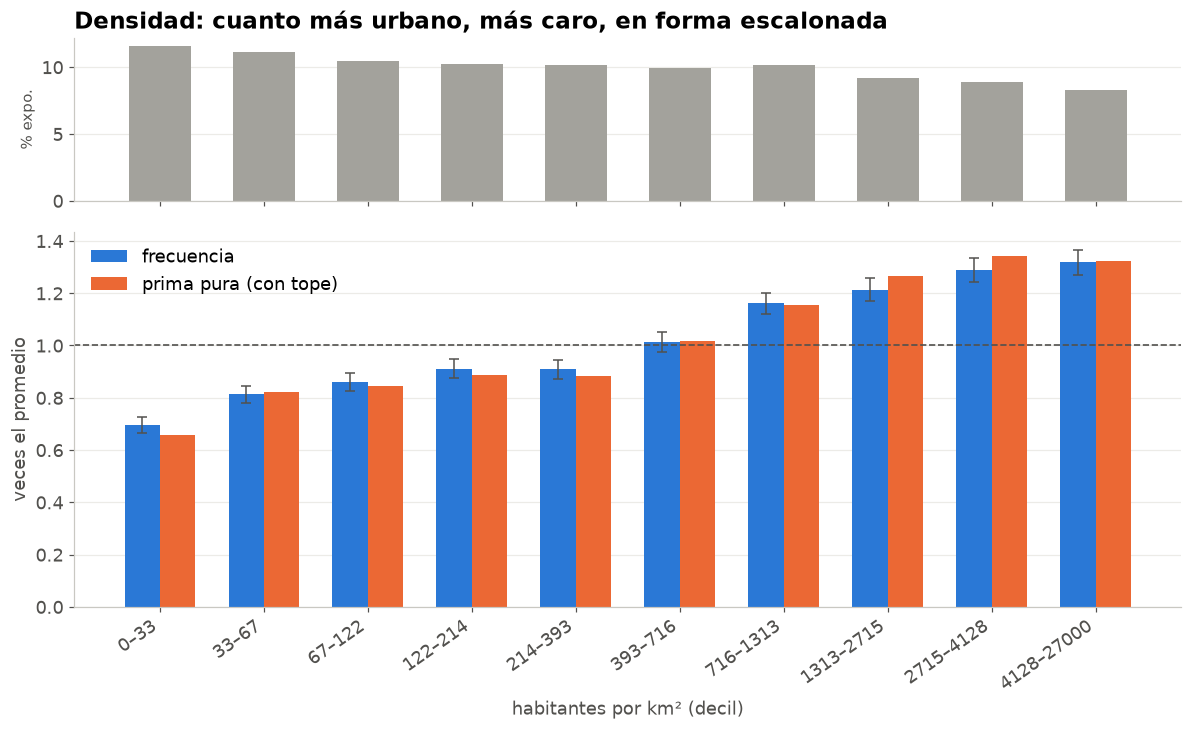

,polizas,pct_exposicion,frecuencia,ic95,rel_frecuencia,rel_prima_pura
0–33,68910,11.614,0.051,0.002,0.696,0.659
33–67,68430,11.098,0.060,0.002,0.813,0.823
67–122,66925,10.423,0.063,0.003,0.860,0.843
122–214,67253,10.249,0.067,0.003,0.911,0.885
214–393,68699,10.181,0.067,0.003,0.910,0.884
393–716,66699,9.913,0.075,0.003,1.012,1.016
716–1313,69809,10.185,0.086,0.003,1.161,1.155
1313–2715,68036,9.197,0.090,0.003,1.213,1.267
2715–4128,67824,8.872,0.095,0.003,1.288,1.343
4128–27000,65428,8.268,0.097,0.004,1.318,1.324


In [13]:
polizas["decil_densidad"] = pd.qcut(polizas["density"], 10, duplicates="drop")
t = resumen("decil_densidad")
t.index = [f"{int(i.left)}–{int(i.right)}" for i in t.index]
grafico(t, "Densidad: cuanto más urbano, más caro, en forma escalonada", "eda_densidad", "habitantes por km² (decil)", rotar=35)
t[COLS]

**Lectura:** es la relación **más ordenada** de todo el EDA: la frecuencia sube casi decil a decil (con dos mesetas), de
**0,70×** en las zonas más rurales a **1,32×** en las más densas, y la prima pura acompaña
(0,66× → 1,32×). Confirma la primera parte de **H2** (más densidad → más frecuencia) con una
variable continua y no solo con `Area`.

### 6.6 Región (13 regiones de 2016)

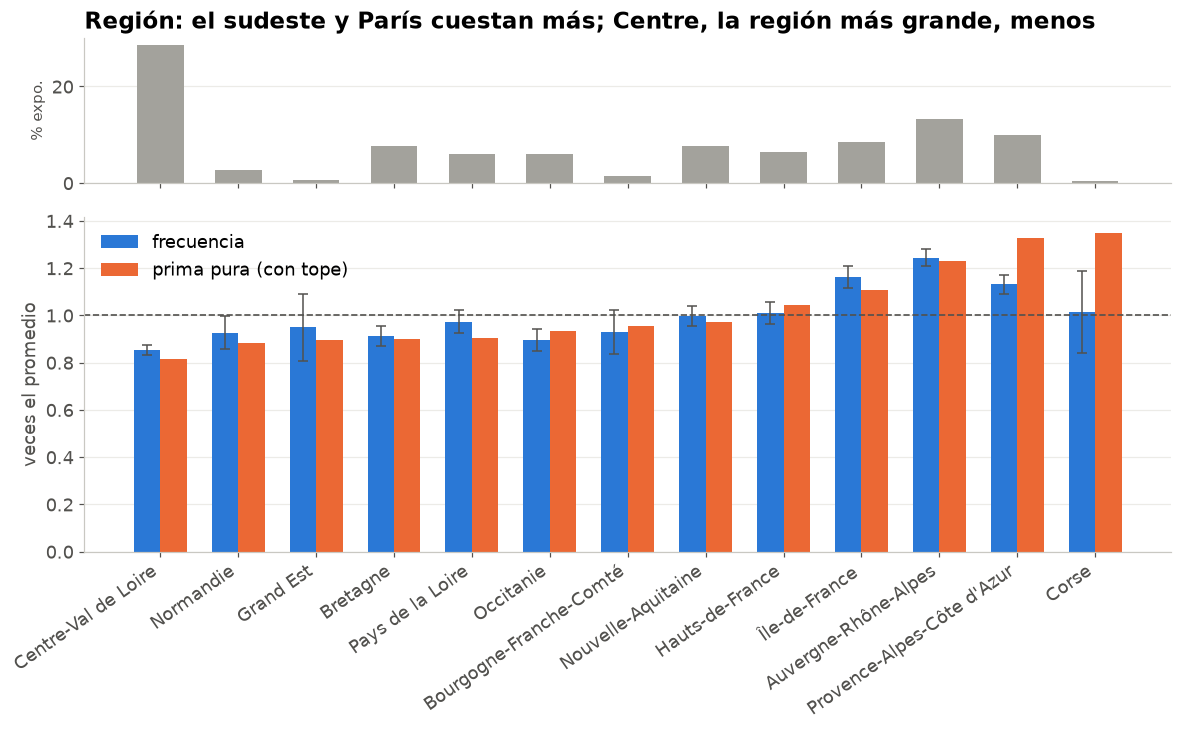

,polizas,pct_exposicion,frecuencia,ic95,rel_frecuencia,rel_prima_pura,densidad_mediana
region_2016,,,,,,,
Centre-Val de Loire,160601,28.660,0.063,0.002,0.854,0.817,95.000
Normandie,19677,2.743,0.068,0.005,0.926,0.881,283.000
Grand Est,5226,0.673,0.070,0.011,0.949,0.895,299.000
Bretagne,42122,7.744,0.067,0.003,0.914,0.901,261.000
Pays de la Loire,38751,6.120,0.072,0.004,0.974,0.905,354.000
Occitanie,52946,6.062,0.066,0.003,0.896,0.933,276.000
Bourgogne-Franche-Comté,11818,1.559,0.069,0.007,0.929,0.956,166.500
Nouvelle-Aquitaine,54942,7.778,0.074,0.003,0.998,0.972,227.000
Hauts-de-France,48269,6.467,0.074,0.004,1.009,1.043,776.000


In [14]:
t = resumen("region_2016").sort_values("rel_prima_pura")
grafico(t, "Región: el sudeste y París cuestan más; Centre, la región más grande, menos", "eda_region", "", rotar=35)
t[COLS + []].assign(densidad_mediana=polizas.groupby("region_2016")["density"].median())

**Lectura:**
- **Más caras:** Corse, Provence-Alpes-Côte d'Azur, Auvergne-Rhône-Alpes e Île-de-France.
- **Más baratas:** Centre-Val de Loire (que es el 29 % de la cartera), Normandie, Bretagne.
- Corse y Grand Est tienen menos del 1 % de exposición: sus intervalos son muy anchos.
- La **densidad mediana** explica buena parte del orden: Île-de-France (4.478 hab/km²) es cara y
  Centre (95 hab/km²) es barata. La región mezcla territorio y urbanización.

## 7. Cruces: ¿el efecto es propio o es confusión con otra variable?

Una variable puede parecer importante solo porque se parece a otra. Lo comprobamos comparando
**dentro de grupos parecidos**.

### 7.1 Diésel contra nafta, dentro del mismo perfil
Si el diésel fuera más caro solo porque lo usan conductores jóvenes o con BonusMalus alto, la
diferencia desaparecería al comparar dentro de cada franja.

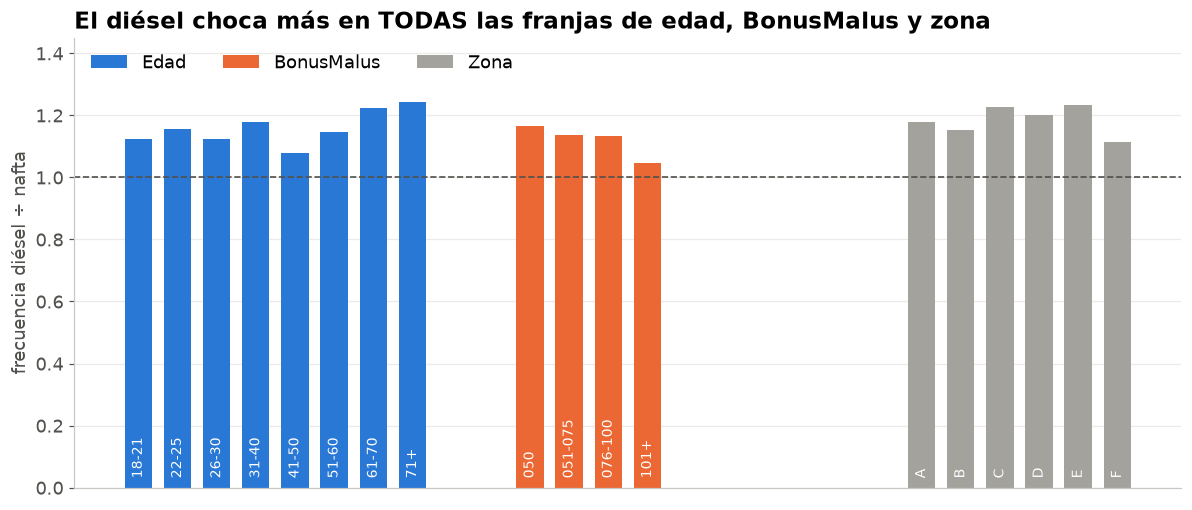

,franja_edad,franja_bm,area
18-21,1.120,NaN,NaN
22-25,1.160,NaN,NaN
26-30,1.120,NaN,NaN
31-40,1.180,NaN,NaN
41-50,1.080,NaN,NaN
51-60,1.140,NaN,NaN
61-70,1.230,NaN,NaN
71+,1.240,NaN,NaN
050,NaN,1.170,NaN
051-075,NaN,1.140,NaN


In [15]:
def ratio_diesel(col):
    f = (polizas.groupby([col, "vehgas"], observed=True)["siniestros"].sum()
         / polizas.groupby([col, "vehgas"], observed=True)["exposure"].sum()).unstack()
    return (f["Diesel"] / f["Regular"]).rename(col)

cruce = pd.concat([ratio_diesel(c) for c in ["franja_edad", "franja_bm", "area"]], axis=1)
fig, ax = plt.subplots(figsize=(11, 4.8))
for k, col in enumerate(["franja_edad", "franja_bm", "area"]):
    r = ratio_diesel(col)
    pos = np.arange(len(r)) + k * 10
    ax.bar(pos, r.values, color=[AZUL, NARANJA, GRIS][k], width=0.7, label=["Edad", "BonusMalus", "Zona"][k])
    for p_, (i, v) in zip(pos, r.items()):
        ax.text(p_, 0.03, str(i), rotation=90, ha="center", va="bottom", fontsize=9, color="white")
ax.axhline(1, color=TINTA, ls="--", lw=1.1)
ax.set_xticks([])
ax.set_ylabel("frecuencia diésel ÷ nafta")
ax.set_ylim(0, 1.45)
ax.legend(frameon=False, ncols=3, loc="upper left")
ax.set_title("El diésel choca más en TODAS las franjas de edad, BonusMalus y zona")
guardar(fig, "eda_diesel_cruce")
cruce.round(2)

**Lectura:** en **todas** las franjas de edad, de BonusMalus y de zona, el diésel tiene entre un
**4 % y un 24 % más** de frecuencia que la nafta. El efecto **no es confusión** con esas variables:
es propio del grupo diésel. *Suposición razonable* (no medible acá): quien compra diésel suele
manejar más kilómetros por año, y los kilómetros no están en el dataset.

### 7.2 La marca B12 y la antigüedad del vehículo

In [16]:
mezcla = pd.crosstab(polizas["vehbrand"], polizas["franja_vehage"],
                     values=polizas["exposure"], aggfunc="sum", normalize="index") * 100
mezcla = mezcla.loc[sorted(mezcla.index, key=lambda m: int(m[1:]))]
mezcla.round(0)

franja_vehage,00,01-02,03-05,06-10,11-15,16+
vehbrand,,,,,,
B1,2.000,10.000,17.000,30.000,27.000,12.000
B2,2.000,11.000,18.000,31.000,28.000,10.000
B3,3.000,15.000,22.000,30.000,22.000,8.000
B4,3.000,14.000,23.000,35.000,20.000,5.000
B5,2.000,9.000,19.000,36.000,25.000,9.000
B6,2.000,12.000,22.000,35.000,23.000,5.000
B10,4.000,14.000,20.000,25.000,21.000,16.000
B11,4.000,15.000,18.000,29.000,23.000,10.000
B12,15.000,45.000,26.000,11.000,3.000,1.000


**Lectura:** B12 es muy distinta: **el 64 % de sus autos tiene 2 años o menos** (contra 10–20 % en
las demás marcas). Su antigüedad media es 2,6 años contra 7–10 del resto. B12 es probablemente una
marca con muchos autos nuevos (o de flota / leasing). Su frecuencia baja puede venir del tipo de
cliente y no de la marca en sí: **no conviene leer la marca de forma aislada**.

### 7.3 Región y densidad

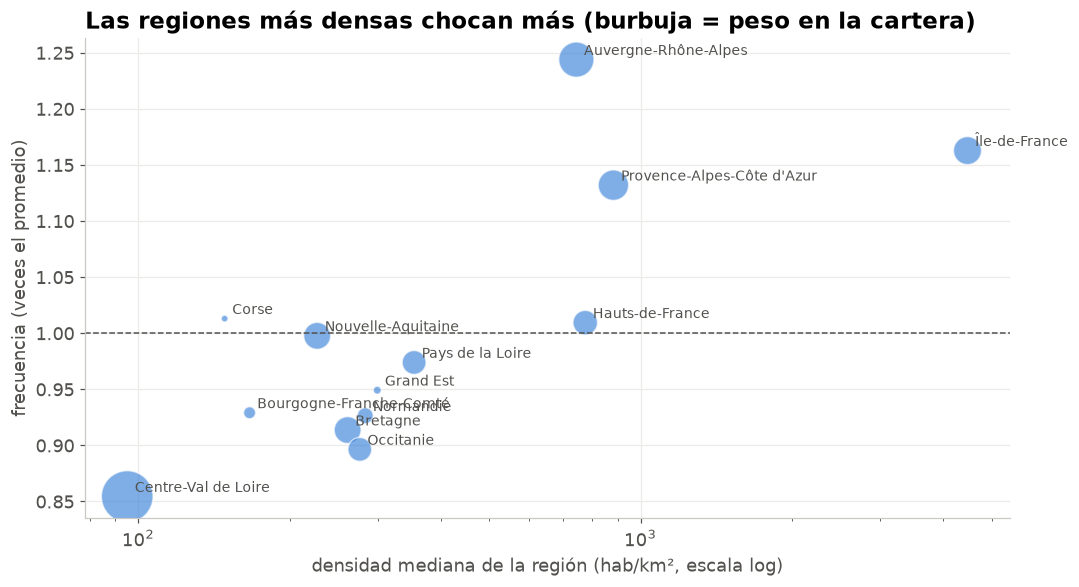

Correlación de Spearman entre densidad mediana y frecuencia regional: 0.63


In [17]:
reg = resumen("region_2016")[["pct_exposicion", "rel_frecuencia"]]
reg["densidad_mediana"] = polizas.groupby("region_2016")["density"].median()
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(reg["densidad_mediana"], reg["rel_frecuencia"], s=reg["pct_exposicion"] * 40,
           color=AZUL, alpha=0.6, edgecolor="white")
for nombre, fila in reg.iterrows():
    ax.annotate(nombre, (fila["densidad_mediana"], fila["rel_frecuencia"]), fontsize=9,
                xytext=(5, 3), textcoords="offset points", color=TINTA)
ax.set_xscale("log")
ax.axhline(1, color=TINTA, ls="--", lw=1)
ax.set_xlabel("densidad mediana de la región (hab/km², escala log)")
ax.set_ylabel("frecuencia (veces el promedio)")
ax.set_title("Las regiones más densas chocan más (burbuja = peso en la cartera)")
ax.grid(True, axis="both")
guardar(fig, "eda_region_densidad")
print("Correlación de Spearman entre densidad mediana y frecuencia regional:",
      round(reg["densidad_mediana"].corr(reg["rel_frecuencia"], method="spearman"), 2))

**Lectura:** las regiones con mayor densidad mediana tienden a tener más frecuencia (correlación
positiva entre regiones). La región no es un efecto independiente: **en buena parte es densidad**.
Para una tarifa, densidad y región no deberían usarse como si fueran independientes (igual que
`Area` y `Density`, Q13).

## 8. Outliers

### 8.1 Montos de los siniestros

In [18]:
m = siniestros["monto"]
print(m.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2).to_string())
print(f"\nSiniestros por encima del tope p99: {int(siniestros['es_grande'].sum())}")
print("Los 5 montos más repetidos:")
repetidos = m.value_counts().head(5)
print((repetidos.to_frame("siniestros").assign(pct=lambda d: (100 * d.siniestros / len(m)).round(1))).to_string())

count      26,444.000
mean        2,265.510
std        29,371.030
min             1.000
25%           685.990
50%         1,172.000
75%         1,212.380
90%         2,767.600
99%        16,451.220
max     4,075,400.560

Siniestros por encima del tope p99: 265
Los 5 montos más repetidos:
           siniestros    pct
monto                       
1,204.000        4792 18.100
1,128.120        3056 11.600
1,172.000        2071  7.800
1,128.000         831  3.100
602.000           433  1.600


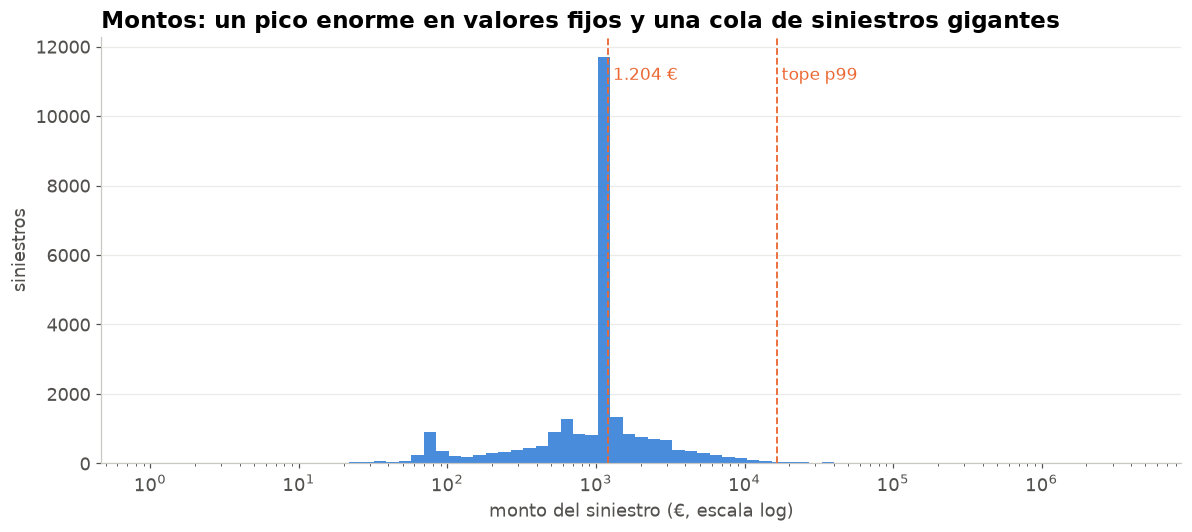

In [19]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(m, bins=np.logspace(0, np.log10(m.max()), 80), color=AZUL, alpha=0.85)
ax.set_xscale("log")
for valor, txt in [(1204, "1.204 €"), (16451.22, "tope p99")]:
    ax.axvline(valor, color=NARANJA, ls="--", lw=1.2)
    ax.text(valor * 1.08, ax.get_ylim()[1] * 0.9, txt, color=NARANJA, fontsize=11)
ax.set_xlabel("monto del siniestro (€, escala log)")
ax.set_ylabel("siniestros")
ax.set_title("Montos: un pico enorme en valores fijos y una cola de siniestros gigantes")
guardar(fig, "eda_montos")

**Lectura:**
- La **mediana es 1.172 €** pero la **media 2.266 €** y el máximo **4,1 millones**: distribución
  muy asimétrica (cola pesada, Q12). Por eso se usa el tope.
- Hay **picos de montos idénticos**: **1.204 €** aparece 4.792 veces (18 % de los siniestros) y
  **1.128,12 €** 3.056 veces (12 %). No es un error: según la documentación del dataset, algunos
  montos son **importes fijos de la convención IRSA-IDA** entre aseguradoras francesas. Para casi un
  tercio de los siniestros, el monto no es el costo real del choque sino un forfait:
  **limitación** a declarar.
- Esto también explica parte de los "siniestros repetidos" de Q6 (misma póliza y mismo monto).

### 8.2 Valores extremos en las variables de la póliza

In [20]:
extremos = pd.Series({
    "VehAge 99 o 100 (código de desconocido, Q10)": (polizas["vehage"] >= 99).sum(),
    "VehAge entre 30 y 98": polizas["vehage"].between(30, 98).sum(),
    "DrivAge > 90 (Q11)": (polizas["drivage"] > 90).sum(),
    "BonusMalus > 150": (polizas["bonusmalus"] > 150).sum(),
    "Exposure < 0,01 años (Q8)": (polizas["exposure"] < 0.01).sum(),
    "Pólizas con 4 o más siniestros": (polizas["siniestros"] >= 4).sum(),
}, name="pólizas")
extremos.to_frame().assign(pct=lambda d: (100 * d["pólizas"] / len(polizas)).round(3))

,pólizas,pct
"VehAge 99 o 100 (código de desconocido, Q10)",48,0.007
VehAge entre 30 y 98,1317,0.194
DrivAge > 90 (Q11),401,0.059
BonusMalus > 150,209,0.031
"Exposure < 0,01 años (Q8)",6877,1.014
Pólizas con 4 o más siniestros,13,0.002


**Lectura:** todos los grupos extremos son **chicos**: el más grande, las pólizas de menos de 4 días, es apenas el 1 % de la cartera; el resto no llega al 0,2 %.
Se dejaron en los datos (ver `docs/05`) y quedan agrupados en las franjas de los extremos, donde
no cambian los resultados. Ninguno justifica borrar registros.

## 9. Control: ¿el lote sospechoso (IDpol ≤ 24.500) cambia algo?

En `docs/05` se comprobó que el lote no cambia la frecuencia global. Lo repetimos para las
variables nuevas de este notebook.

In [21]:
sin_lote = polizas[polizas["flag_lote_idpol_bajo"] == 0]
filas = []
for col in ["vehgas", "franja_vehage"]:
    a = resumen(col)["rel_frecuencia"]
    b = resumen(col, sin_lote)["rel_frecuencia"]
    filas.append(pd.DataFrame({"variable": col, "con lote": a, "sin lote": b, "diferencia": b - a}))
pd.concat(filas).round(3)

,variable,con lote,sin lote,diferencia
Diesel,vehgas,1.068,1.070,0.002
Regular,vehgas,0.938,0.939,0.001
00,franja_vehage,0.959,0.968,0.009
01-02,franja_vehage,0.991,0.993,0.002
03-05,franja_vehage,1.006,1.006,0.000
06-10,franja_vehage,1.097,1.098,0.001
11-15,franja_vehage,0.987,0.989,0.001
16+,franja_vehage,0.745,0.746,0.001


**Lectura:** las relatividades cambian en milésimas: el lote **no afecta** ninguna conclusión de este EDA.

## 10. Conclusiones del EDA

| Variable | ¿Qué muestra? | ¿Es confiable? | ¿Sirve para tarifar? |
|---|---|---|---|
| **BonusMalus** (ver 02) | El efecto más fuerte: 0,68× a 4,9× | Sí, pero la franja 101+ es el 1 % de la cartera | **Sí, la principal** |
| **Edad** (ver 02) | 18–21 ≈ 3,6× | Mezclada con BonusMalus (ρ = −0,57) | Sí, junto con BonusMalus, no por separado |
| **Densidad** | Escalón ordenado de 0,70× a 1,32× | Sí: todos los deciles tienen ≈ 10 % de la cartera | **Sí** (una sola: densidad **o** Area **o** región) |
| **Combustible** | Diésel ≈ 14 % más frecuencia | Sí: se mantiene dentro de cada edad, BM y zona | **Sí** |
| **Antigüedad del vehículo** | 16+ años ≈ 30 % más barato | Sí (intervalo no toca el 1,0) | Sí, en pocas franjas |
| **Región** | Sudeste y París caros; Centre barato | Parcial: en buena parte es densidad; regiones chicas inestables | Con cuidado, no junto con densidad |
| **Potencia** | Efecto débil, sube algo con potencias altas | Potencias 12+ casi sin cartera | Agrupada en 3–4 franjas |
| **Marca** | B12 barata, B11 cara | Débil: B12 está mezclada con autos nuevos; marca anónima | No por sí sola |

**Lo que este EDA agrega a la historia**
1. Además del **conductor** (edad, BonusMalus), el **territorio** (densidad) y el **uso del auto**
   (combustible, antigüedad) también separan perfiles de riesgo.
2. Varias variables **se pisan entre sí** (edad–BonusMalus, densidad–región–Area, marca–antigüedad).
   Mirar una variable por vez exagera o confunde efectos: el siguiente paso natural es un
   **modelo multivariado** (GLM Poisson) que estime todos los efectos a la vez.
3. Nuevas **limitaciones**: casi un tercio de los montos son importes fijos de convención (IRSA),
   y la cartera está concentrada en Centre-Val de Loire, así que no representa a toda Francia.

Los gráficos quedaron en `presentacion/img/eda_*.png` para la presentación.